# Imports

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

# Point Processes

We are dealing with two csv files.Important to note that the dataset has been anonymized .

`features.csv`: Contains patient features. Does not provide information about what each of this features mean. Labeled as F0,F1,..., F7

`timelines.csv`: Patient event times. Time is encoded in months and as a relative difference with respect to the previous event.

In [6]:
features = pd.read_csv("features.csv", sep=";")
timelines = pd.read_csv("timelines.csv", sep=";")

In [7]:
features

,ID,F0,F1,F2,F3,F4,F5,F6,F7
0,GIMO0741213000,0,0.260539,1,0,0,0,0,0
1,MAMA1770428016,1,0.343443,0,1,0,0,0,0
2,NHC14160717,1,0.740823,0,1,0,0,0,0
3,ARAR1670527002,1,0.459585,0,0,1,1,0,0
4,14665507,1,0.437052,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...
1107,BETA1850704002,1,0.319240,0,0,1,0,1,1
1108,14031598,1,0.477108,0,1,0,0,0,1
1109,LUCA1741008007,1,0.432726,0,1,0,0,1,1
1110,PALO1760413000,1,0.418051,0,1,0,0,0,1


In [8]:
timelines

,ID,time_1,time_2,time_3,time_4,time_5,time_6,time_7,time_8,time_9,time_10,time_11
0,GIMO0741213000,14.113621,1.300479,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,MAMA1770428016,8.813142,0.002738,0.884326,0.087611,0.169747,0.019165,0.024641,0.804928,0.032854,0.156057,0.073923
2,NHC14160717,7.745380,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,ARAR1670527002,7.477070,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,14665507,6.965092,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
1107,BETA1850704002,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1108,14031598,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1109,LUCA1741008007,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1110,PALO1760413000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


## Preprocessing

Data has been anonymized, however, we will analyze it briefly to check for NA values as well as to see the data we are dealing with.

For simplicity, we will merge both datasets into 1.

We see that 7 of our variables are binary, we will plot them 

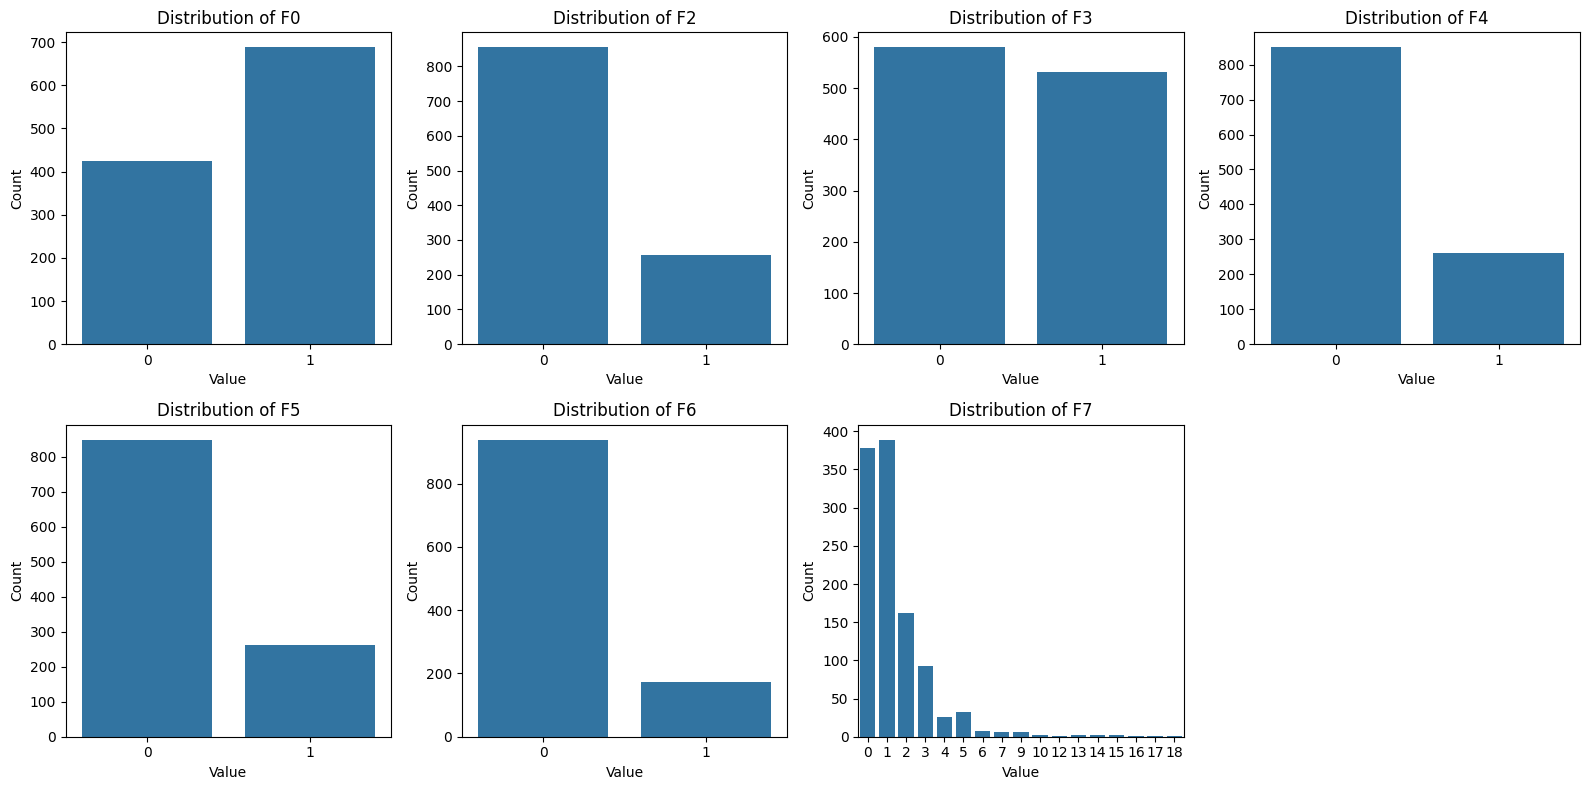

In [25]:
cols = ['F0', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.countplot(data=features, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Count')

# Unused plots
axes[-1].remove() 

plt.tight_layout()
plt.show()

If an event has not happened at time 0 it is a value of 0.0. And the following timestamps will have a value of 0. Therefore, we have to remove patients which do not follow this structure.


For Hawkes process, we have to define the events with respect to a common starting point rather than the previous timestamp

In [27]:
for i in range(1, 10):
    invalid = (timelines[f'time_{i}'] == 0) & (timelines[f'time_{i+1}'] > 0)
    print(f"time_{i} violations:", invalid.sum())

time_1 violations: 1
time_2 violations: 0
time_3 violations: 0
time_4 violations: 0
time_5 violations: 0
time_6 violations: 0
time_7 violations: 0
time_8 violations: 0
time_9 violations: 0


In [29]:
# We have a single patient, whose value is larger than 0 at time 2 when at time one we had a value of 0
timelines[(timelines["time_1"] == 0) & (timelines["time_2"]>0.0)]

,ID,time_1,time_2,time_3,time_4,time_5,time_6,time_7,time_8,time_9,time_10,time_11
138,AYZA1840525007,0.0,0.087611,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [30]:
# Removing the patient.
timelines[~(timelines["ID"]=="AYZA1840525007")]
features[~(features["ID"]=="AYZA1840525007")]

,ID,F0,F1,F2,F3,F4,F5,F6,F7
0,GIMO0741213000,0,0.260539,1,0,0,0,0,0
1,MAMA1770428016,1,0.343443,0,1,0,0,0,0
2,NHC14160717,1,0.740823,0,1,0,0,0,0
3,ARAR1670527002,1,0.459585,0,0,1,1,0,0
4,14665507,1,0.437052,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...
1107,BETA1850704002,1,0.319240,0,0,1,0,1,1
1108,14031598,1,0.477108,0,1,0,0,0,1
1109,LUCA1741008007,1,0.432726,0,1,0,0,1,1
1110,PALO1760413000,1,0.418051,0,1,0,0,0,1


## Clustering

Clustering must only be applied on the features. Timelines will be used on the posterior Hawkes process.

`Calinski-Harabasz`: Ratio of the sum of inter-cluster dispersion and the sum of intra-cluster dispersion for all clusters. The higher the better

`Davies-Bouldin`: Average similarity of each cluster with a cluster more similar to it. The lower the average similarity is, the better. Similarity is defined as the ratio of within-cluster scatter to between-cluster distances

`Silhouette Score`: How well each data point fits within its assignated cluster and how well separated it is from other clusters. Returns a value between 1 and -1. 0 indicates overlap, negative values means a point has been incorrectly assigned.

`Elbow Method`: We compute the Within-Cluster Sum of Squares (WCSS) for various values of k. We will obtain a plot in a decreasing manner, we will select the cluster located at the elbow.

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

In [33]:
# Removing the ID temporarily
feature_ID = features["ID"]
features = features.drop(["ID"], axis=1)

In [34]:
# Standardizing so every feature has the same weight in the distances
data_norm = StandardScaler().fit_transform(features)

K = list(range(2,9))

wcss, ch_scores, db_scores, sh_scores = [], [], [], []
for k in K:
    kmeans = KMeans(n_clusters=k, random_state= 42, init="k-means++").fit(data_norm)
    wcss.append(kmeans.inertia_)
    labels = kmeans.labels_
    ch_scores.append(calinski_harabasz_score(data_norm, labels))
    db_scores.append(davies_bouldin_score(data_norm, labels))
    sh_scores.append(silhouette_score(data_norm, labels))

metrics_df = pd.DataFrame({
    "K": K,
    "WCSS": wcss,
    "Silhouette Score": sh_scores,
    "Calinski-Harabasz": ch_scores,
    "Davies-Bouldin": db_scores
})

print(metrics_df.to_string(index=False))

 K        WCSS  Silhouette Score  Calinski-Harabasz  Davies-Bouldin
 2 7164.929458          0.248704         268.179654        1.552462
 3 5563.805269          0.322042         332.093215        1.366801
 4 4894.364262          0.331579         301.967199        1.290995
 5 4400.408097          0.294573         282.736290        1.302202
 6 4109.863599          0.306896         257.598177        1.331043
 7 3620.292154          0.319214         268.378763        1.226659
 8 3306.142086          0.334087         266.655342        1.210312


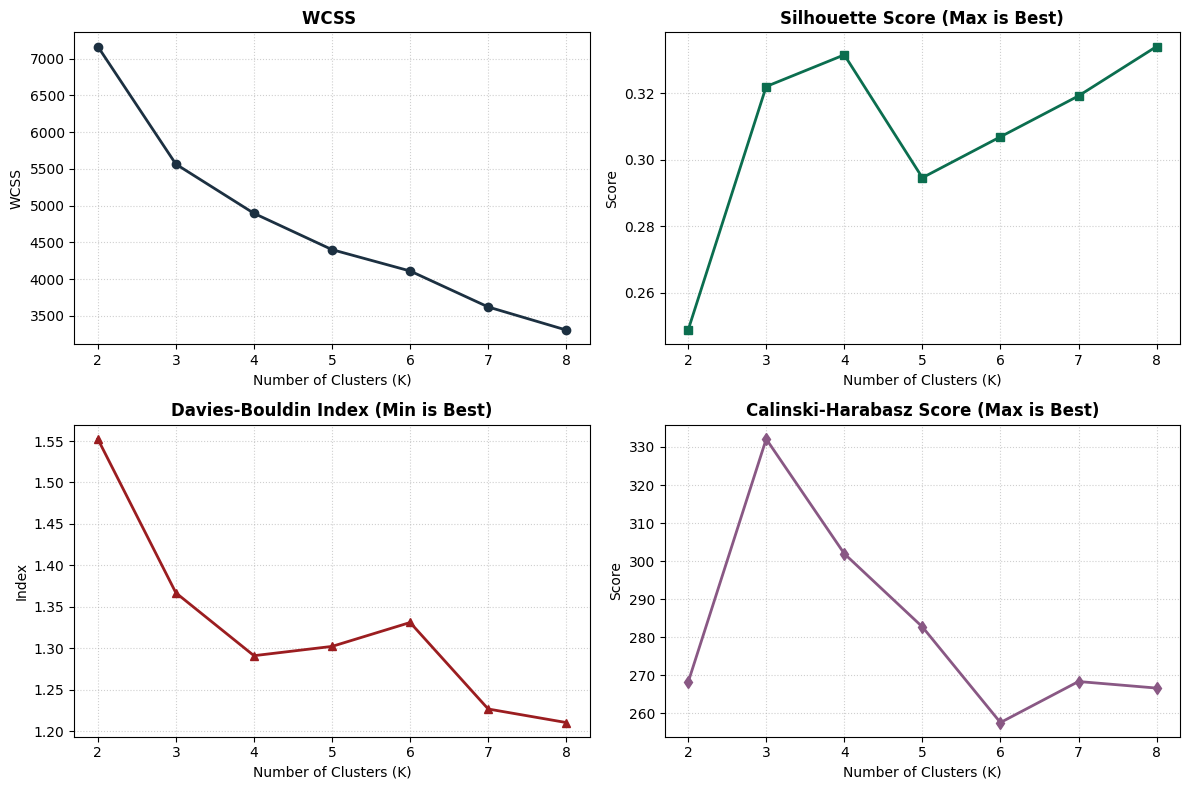

In [35]:

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

#  WCSS /Inertia (Elbow)
axs[0, 0].plot(K, wcss, marker="o", color="#1C3041", linewidth=2)
axs[0, 0].set_title("WCSS ", fontweight="bold")
axs[0, 0].set_xlabel("Number of Clusters (K)")
axs[0, 0].set_ylabel("WCSS")
axs[0, 0].grid(True, linestyle=":", alpha=0.6)

# Silhouette Score (Higher = Better)
axs[0, 1].plot(K, sh_scores, marker="s", color="#0B6E4F", linewidth=2)
axs[0, 1].set_title("Silhouette Score (Max is Best)", fontweight="bold")
axs[0, 1].set_xlabel("Number of Clusters (K)")
axs[0, 1].set_ylabel("Score")
axs[0, 1].grid(True, linestyle=":", alpha=0.6)

#  Davies-Bouldin Index (Lower = Better)
axs[1, 0].plot(K, db_scores, marker="^", color="#9B1D20", linewidth=2)
axs[1, 0].set_title("Davies-Bouldin Index (Min is Best)", fontweight="bold")
axs[1, 0].set_xlabel("Number of Clusters (K)")
axs[1, 0].set_ylabel("Index")
axs[1, 0].grid(True, linestyle=":", alpha=0.6)

# Calinski-Harabasz Score (Higher = Better)
axs[1, 1].plot(K, ch_scores, marker="d", color="#895884", linewidth=2)
axs[1, 1].set_title("Calinski-Harabasz Score (Max is Best)", fontweight="bold")
axs[1, 1].set_xlabel("Number of Clusters (K)")
axs[1, 1].set_ylabel("Score")
axs[1, 1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

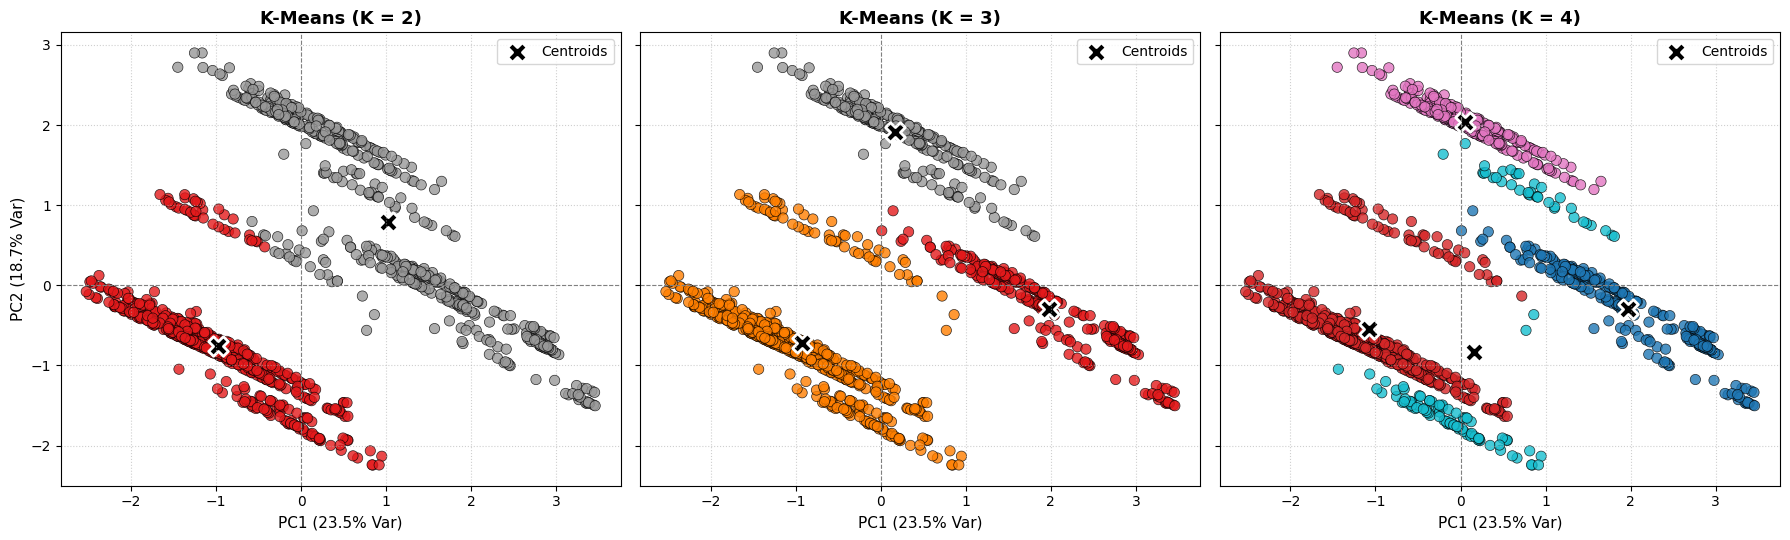

In [ ]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(features)
pca_2d = PCA(n_components=2)
x_pca_2d = pca_2d.fit_transform(scaled_data)
var_exp = pca_2d.explained_variance_ratio_ * 100

fig, axs = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
k_values = [2, 3, 4]

for i, k in enumerate(k_values):
    ax = axs[i]
    kmeans = KMeans(n_clusters=k, random_state=42, init="k-means++", n_init=10)
    labels = kmeans.fit_predict(scaled_data)

    # Project cluster centroids to the 2D PCA space
    centers_2d = pca_2d.transform(kmeans.cluster_centers_)

    scatter = ax.scatter(
        x_pca_2d[:, 0],
        x_pca_2d[:, 1],
        c=labels,
        cmap="Set1" if k <= 3 else "tab10",
        s=55,
        alpha=0.8,
        edgecolors="k",
        linewidths=0.5,
    )

    # Plot projected centroids
    ax.scatter(
        centers_2d[:, 0],
        centers_2d[:, 1],
        c="black",
        marker="X",
        s=200,
        linewidths=2,
        edgecolors="white",
        label="Centroids",
    )

    ax.set_title(f"K-Means (K = {k})", fontsize=13, fontweight="bold")
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Var)", fontsize=11)
    if i == 0:
        ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Var)", fontsize=11)

    ax.grid(True, linestyle=":", alpha=0.6)
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [40]:
# Same metrics for Spectral Clustering (the method finally used), on the same standardized data
sp_ch, sp_db, sp_sh = [], [], []
for k in K:
    labels = SpectralClustering(
        n_clusters=k,
        affinity="nearest_neighbors",
        n_neighbors=15,
        assign_labels="kmeans",
        random_state=42,
        n_jobs=-1,
    ).fit_predict(data_norm)
    sp_ch.append(calinski_harabasz_score(data_norm, labels))
    sp_db.append(davies_bouldin_score(data_norm, labels))
    sp_sh.append(silhouette_score(data_norm, labels))

spectral_metrics_df = pd.DataFrame({
    "K": K,
    "Silhouette Score": sp_sh,
    "Calinski-Harabasz": sp_ch,
    "Davies-Bouldin": sp_db
})

print(spectral_metrics_df.to_string(index=False))

c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\manifold\_spectral_embeddin

 K  Silhouette Score  Calinski-Harabasz  Davies-Bouldin
 2          0.144033          64.222487        1.696667
 3          0.149200          96.650611        1.989279
 4          0.090607          82.218506        1.861185
 5          0.095464          92.577117        1.730671
 6          0.159759         116.348551        1.593572
 7          0.249373         170.069025        1.439629
 8          0.255730         164.545614        1.448668


c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\19aca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


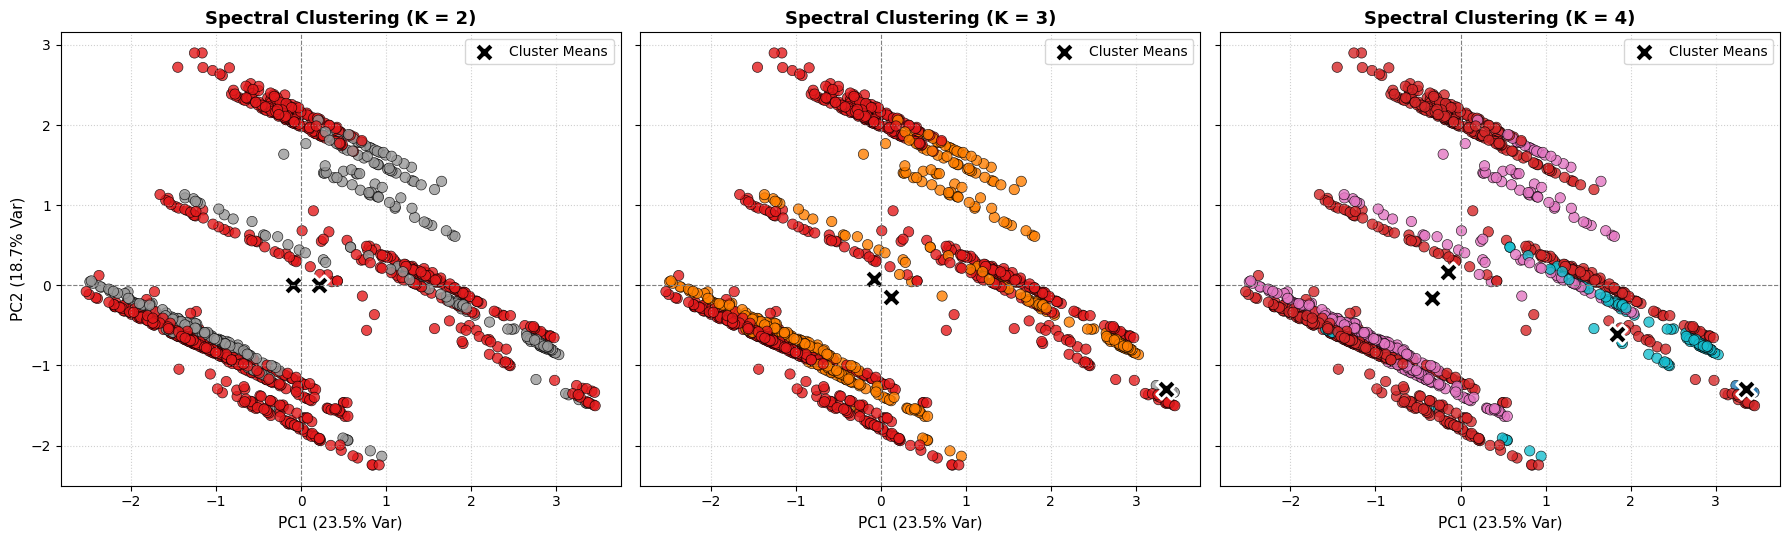

In [44]:
import numpy as np
scaler = StandardScaler()
scaled_data = scaler.fit_transform(features)
pca_2d = PCA(n_components=2)
x_pca_2d = pca_2d.fit_transform(scaled_data)
var_exp = pca_2d.explained_variance_ratio_ * 100

fig, axs = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
k_values = [2, 3, 4]

for i, k in enumerate(k_values):
    ax = axs[i]
    
    # Spectral Clustering with nearest-neighbors affinity graph
    spectral = SpectralClustering(
        n_clusters=k,
        affinity='nearest_neighbors',  
        
        n_neighbors=5,                
        assign_labels='kmeans',
        random_state=42,
        n_jobs=-1
    )
    labels = spectral.fit_predict(scaled_data)

    centers_2d = np.array([
        x_pca_2d[labels == cluster_id].mean(axis=0)
        for cluster_id in range(k)
    ])

    scatter = ax.scatter(
        x_pca_2d[:, 0],
        x_pca_2d[:, 1],
        c=labels,
        cmap="Set1" if k <= 3 else "tab10",
        s=55,
        alpha=0.8,
        edgecolors="k",
        linewidths=0.5,
    )

    # Plot empirical cluster means
    ax.scatter(
        centers_2d[:, 0],
        centers_2d[:, 1],
        c="black",
        marker="X",
        s=200,
        linewidths=2,
        edgecolors="white",
        label="Cluster Means",
    )

    ax.set_title(f"Spectral Clustering (K = {k})", fontsize=13, fontweight="bold")
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Var)", fontsize=11)
    if i == 0:
        ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Var)", fontsize=11)

    ax.grid(True, linestyle=":", alpha=0.6)
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()